<a href="https://colab.research.google.com/github/EnzoSalvini/Calculo_numerico/blob/main/Atividade_Erro_Interpolacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

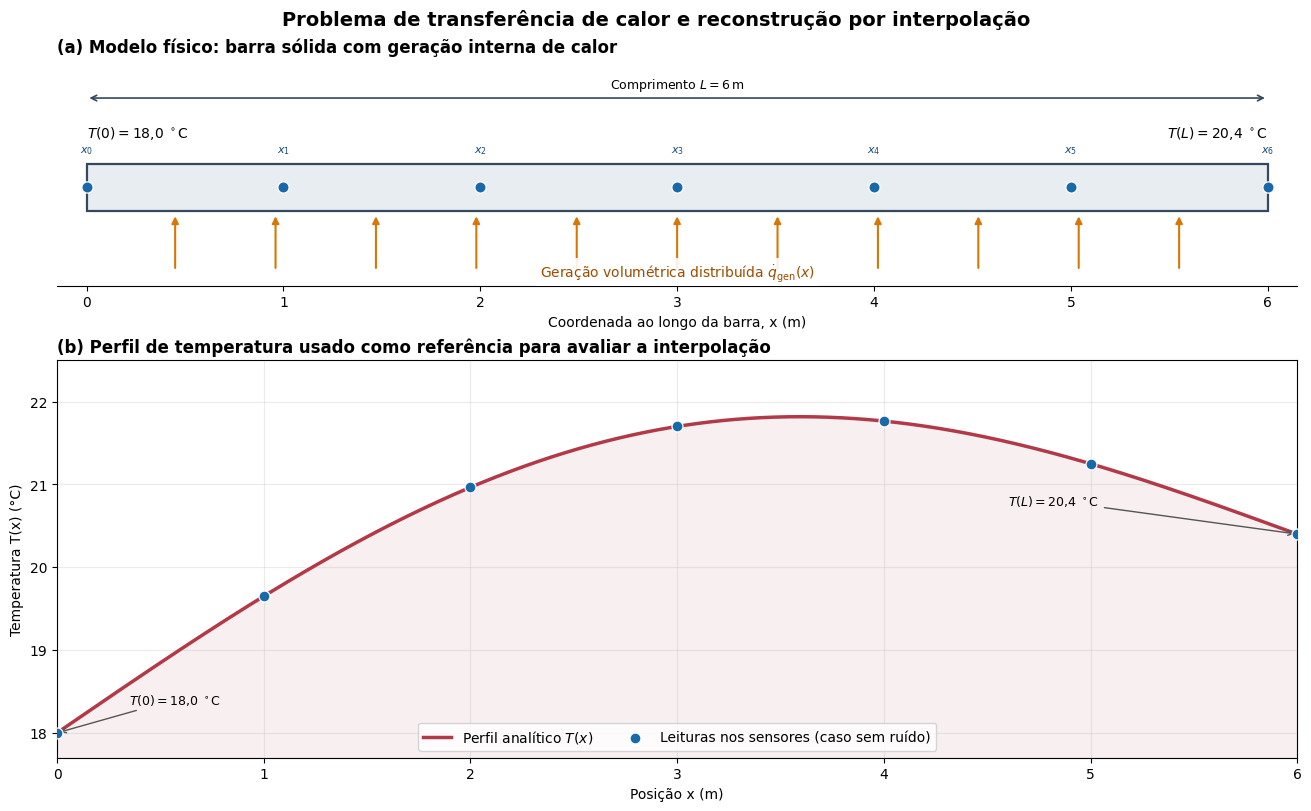

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [ ]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




In [ ]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# TODO: calcular a tabela de métricas na malha fina
# metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
# display(metricas_7)

# TODO: sobreponha os quatro métodos à função verdadeira e marque os nós
# TODO: gráfico dos erros assinados método a método.
# Dica: erro = metodo(x_fino) - T_fino

=== Tabela de Erros (Dados Exatos) ===


,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


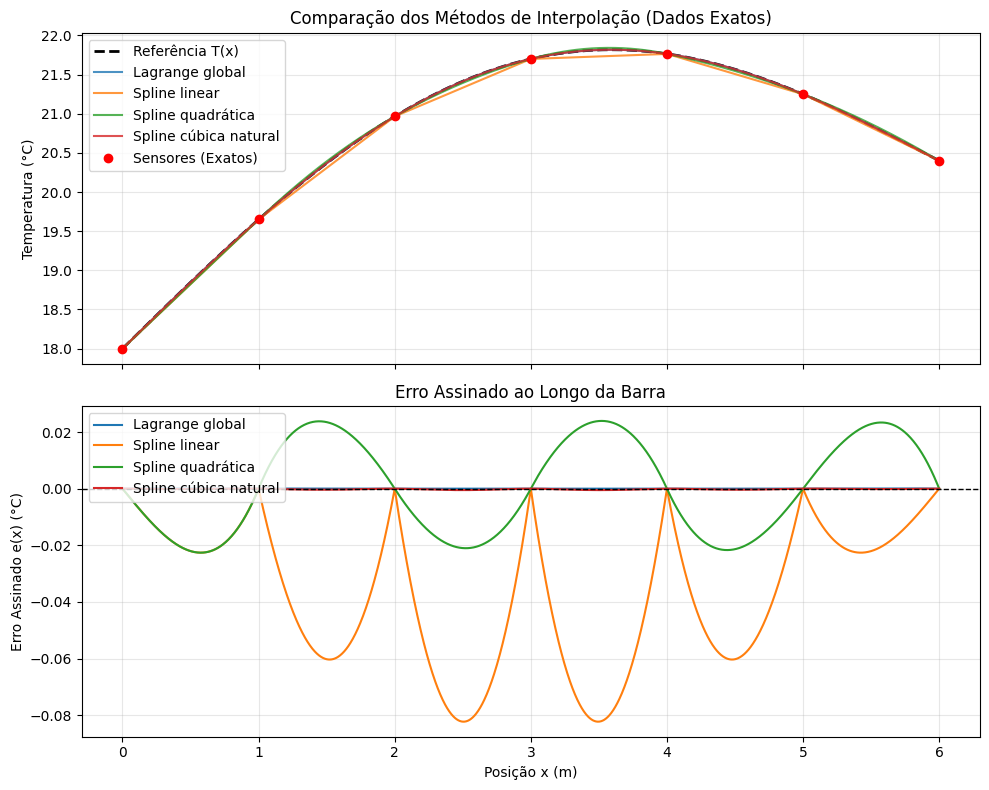

In [ ]:
# 1. Definir 7 posições igualmente espaçadas (incluindo as extremidades 0 e L)
x_sensores_exatos = np.linspace(0, L, 7)
y_sensores_exatos = temperatura_real(x_sensores_exatos)

# 2. Criar o dicionário de métodos
metodos_exatos = criar_metodos(x_sensores_exatos, y_sensores_exatos)

# 3. Calcular as métricas comparando na malha fina (x_fino)
tabela_erros_exatos = calcular_metricas(metodos_exatos, x_fino, T_fino)
print("=== Tabela de Erros (Dados Exatos) ===")
display(tabela_erros_exatos)

# 4. Gráficos comparativos (Temperaturas e Erros Assinados)
fig, (ax_temp, ax_erro) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Painel Superior: Reconstrução das temperaturas
ax_temp.plot(x_fino, T_fino, 'k--', label="Referência T(x)", linewidth=2)
for nome, metodo in metodos_exatos.items():
    ax_temp.plot(x_fino, metodo(x_fino), label=nome, alpha=0.8, linewidth=1.5)
ax_temp.scatter(x_sensores_exatos, y_sensores_exatos, color='red', zorder=5, label="Sensores (Exatos)")
ax_temp.set_ylabel("Temperatura (°C)")
ax_temp.set_title("Comparação dos Métodos de Interpolação (Dados Exatos)")
ax_temp.legend(loc="upper left", frameon=True)
ax_temp.grid(True, alpha=0.3)

# Painel Inferior: Erros assinados e(x) = T_interp(x) - T_ref(x)
for nome, metodo in metodos_exatos.items():
    erro_assinado = np.asarray(metodo(x_fino)) - T_fino
    ax_erro.plot(x_fino, erro_assinado, label=nome, linewidth=1.5)
ax_erro.axhline(0, color='black', linestyle='--', linewidth=1)
ax_erro.set_xlabel("Posição x (m)")
ax_erro.set_ylabel("Erro Assinado e(x) (°C)")
ax_erro.set_title("Erro Assinado ao Longo da Barra")
ax_erro.legend(loc="upper left", frameon=True)
ax_erro.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

# TODO: compare N = 5, 9, 13 e 17
# Para cada N, construa Lagrange com nós equiespaçados e com nós de Chebyshev.
# Calcule Emax e RMSE usando x_fino e T_fino.
# Organize os resultados em um DataFrame.

# tabela_nos = ...
# display(tabela_nos)
resultados_etapa2 = []
valores_N = [5, 9, 13, 17]

for N in valores_N:
    # 1. Nós equiespaçados
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    lag_eq = BarycentricInterpolator(x_eq, y_eq)
    erro_eq = lag_eq(x_fino) - T_fino

    resultados_etapa2.append({
        "N": N,
        "Distribuição": "Equiespaçada",
        "Erro máximo (°C)": np.max(np.abs(erro_eq)),
        "RMSE (°C)": np.sqrt(np.mean(erro_eq**2))
    })

    # 2. Nós de Chebyshev-Lobatto
    x_cheb = nos_chebyshev_lobatto(x_min, x_max, N)
    y_cheb = temperatura_real(x_cheb)
    lag_cheb = BarycentricInterpolator(x_cheb, y_cheb)
    erro_cheb = lag_cheb(x_fino) - T_fino

    resultados_etapa2.append({
        "N": N,
        "Distribuição": "Chebyshev-Lobatto",
        "Erro máximo (°C)": np.max(np.abs(erro_cheb)),
        "RMSE (°C)": np.sqrt(np.mean(erro_cheb**2))
    })

tabela_nos = pd.DataFrame(resultados_etapa2)
display(tabela_nos)

,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçada,4.530257e-03,2.159567e-03
1,5,Chebyshev-Lobatto,2.326599e-03,1.532697e-03
2,9,Equiespaçada,1.043537e-06,3.438146e-07
3,9,Chebyshev-Lobatto,2.167582e-07,1.202332e-07
4,13,Equiespaçada,5.910294e-11,1.545469e-11
5,13,Chebyshev-Lobatto,3.623768e-12,1.931992e-12
6,17,Equiespaçada,1.989520e-12,2.445428e-13
7,17,Chebyshev-Lobatto,1.421085e-14,3.746292e-15


- Convergência extremamente rápida em ambos os casos: Diferente da clássica função de Runge ($f(x) = \frac{1}{1+25x^2}$), onde nós equiespaçados explodem em erro conforme $N$ cresce, aqui tanto os nós equiespaçados quanto os de Chebyshev reduzem o erro até o limite da precisão de máquina ($\approx 10^{-14}$ ou $10^{-15}\,^\circ\text{C}$) quando $N=17$.
- Por que isso acontece com $T(x)$? O perfil analítico $T(x) = 18 + 2.4\xi + 2.5\sin(\pi\xi)$ é uma função inteira (analítica em todo o plano complexo, infinitamente diferenciável $C^\infty$, sem polos próximos ao eixo real). Suas derivadas de ordem $N$ são limitadas por $\left(\frac{\pi}{L}\right)^N$, o que faz com que o termo $\frac{T^{(N)}(\xi)}{N!}$ da fórmula do erro de interpolação decaia muito mais rápido do que o crescimento do termo nodal $\prod (x - x_i)$.
- Diferença entre Equiespaçada e Chebyshev: Mesmo que ambos convirjam nesse perfil suave, para valores intermediários de $N$ (como $N=5$ e $N=9$), os nós de Chebyshev-Lobatto ainda apresentam um erro máximo ($E_{\max}$) menor, pois minimizam o máximo do polinômio nodal $\max_{x \in [a,b]} \left\vert{}\prod_{i=0}^{N-1} (x - x_i)\right\vert{}$, evitando o acúmulo de erro próximo às bordas $x=0$ e $x=6$.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

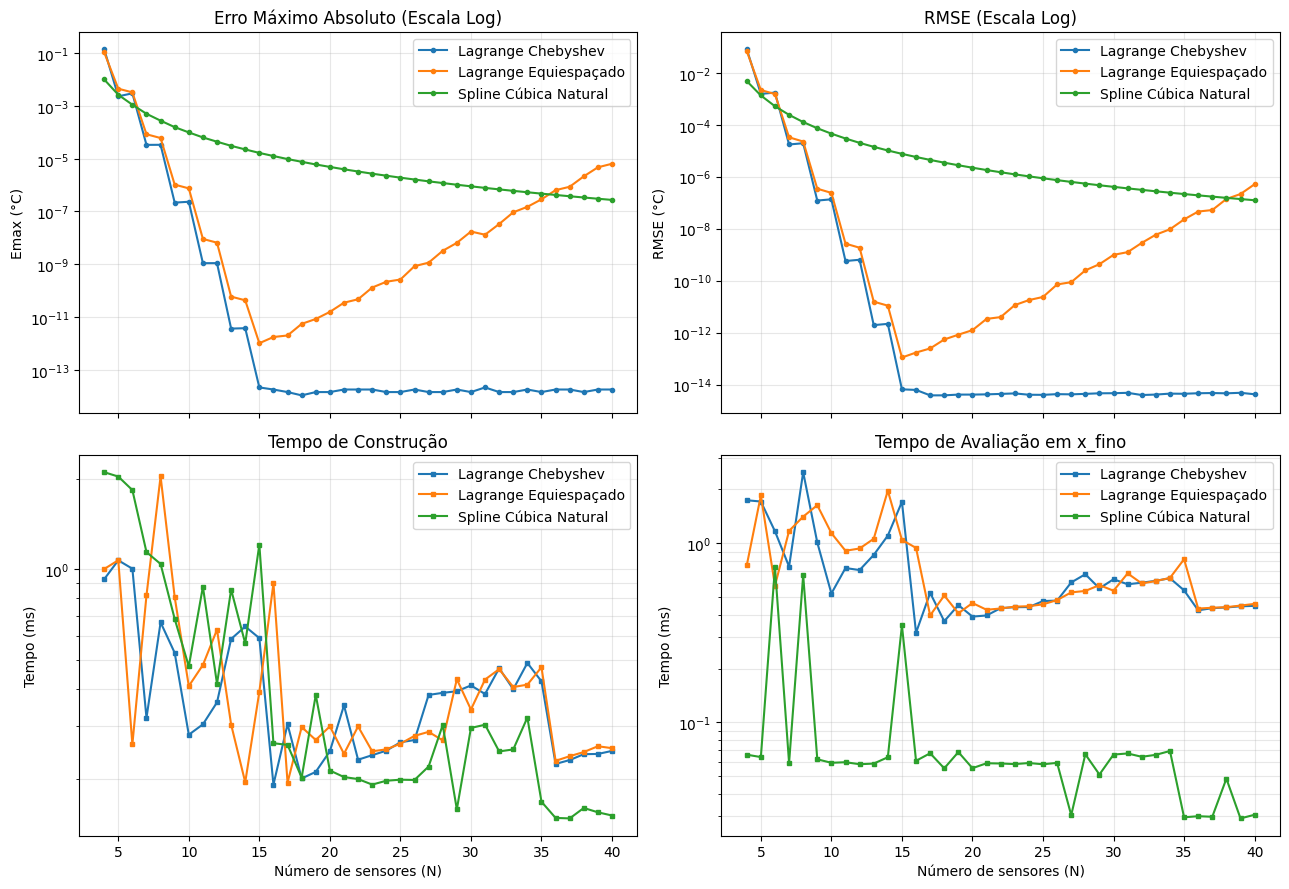

In [ ]:
import time

Ns = np.arange(4, 41)
resultados_etapa3 = []

def medir_tempo(func, repeticoes=15):
    t0 = time.perf_counter()
    for _ in range(repeticoes):
        res = func()
    return (time.perf_counter() - t0) / repeticoes, res

for N in Ns:
    # Malhas de sensores
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)

    x_cheb = nos_chebyshev_lobatto(x_min, x_max, N)
    y_cheb = temperatura_real(x_cheb)

    # 1. Lagrange Equiespaçado
    t_const_leq, interp_leq = medir_tempo(lambda: BarycentricInterpolator(x_eq, y_eq))
    t_aval_leq, y_pred_leq = medir_tempo(lambda: interp_leq(x_fino))
    err_leq = y_pred_leq - T_fino

    # 2. Lagrange Chebyshev
    t_const_lch, interp_lch = medir_tempo(lambda: BarycentricInterpolator(x_cheb, y_cheb))
    t_aval_lch, y_pred_lch = medir_tempo(lambda: interp_lch(x_fino))
    err_lch = y_pred_lch - T_fino

    # 3. Spline Cúbica Natural (em nós equiespaçados)
    t_const_spl, interp_spl = medir_tempo(lambda: CubicSpline(x_eq, y_eq, bc_type="natural"))
    t_aval_spl, y_pred_spl = medir_tempo(lambda: interp_spl(x_fino))
    err_spl = y_pred_spl - T_fino

    for nome, err, tc, ta in [
        ("Lagrange Equiespaçado", err_leq, t_const_leq, t_aval_leq),
        ("Lagrange Chebyshev", err_lch, t_const_lch, t_aval_lch),
        ("Spline Cúbica Natural", err_spl, t_const_spl, t_aval_spl)
    ]:
        resultados_etapa3.append({
            "N": N,
            "Método": nome,
            "Emax": np.max(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err**2)),
            "Tempo Construção (ms)": tc * 1000,
            "Tempo Avaliação (ms)": ta * 1000
        })

df_etapa3 = pd.DataFrame(resultados_etapa3)

# --- Gráficos em Escala Logarítmica ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

for nome, grupo in df_etapa3.groupby("Método"):
    axes[0, 0].semilogy(grupo["N"], grupo["Emax"], marker="o", markersize=3, label=nome)
    axes[0, 1].semilogy(grupo["N"], grupo["RMSE"], marker="o", markersize=3, label=nome)
    axes[1, 0].semilogy(grupo["N"], grupo["Tempo Construção (ms)"], marker="s", markersize=3, label=nome)
    axes[1, 1].semilogy(grupo["N"], grupo["Tempo Avaliação (ms)"], marker="s", markersize=3, label=nome)

axes[0, 0].set_title("Erro Máximo Absoluto (Escala Log)")
axes[0, 0].set_ylabel("Emax (°C)")

axes[0, 1].set_title("RMSE (Escala Log)")
axes[0, 1].set_ylabel("RMSE (°C)")

axes[1, 0].set_title("Tempo de Construção")
axes[1, 0].set_ylabel("Tempo (ms)")
axes[1, 0].set_xlabel("Número de sensores (N)")

axes[1, 1].set_title("Tempo de Avaliação em x_fino")
axes[1, 1].set_ylabel("Tempo (ms)")
axes[1, 1].set_xlabel("Número de sensores (N)")

for ax in axes.flat:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

1 - Haverá um único método superior para todo $N$?
- Não. A superioridade muda de acordo com a faixa de $N$ e com a restrição física do problema:
  - Para $N$ pequeno a moderado ($4 \le N \lesssim 16$): Os métodos globais de Lagrange (especialmente Chebyshev) apresentam convergência exponencial (espectral) para essa função analítica, atingindo o piso da precisão de ponto flutuante ($\approx 10^{-15}\,^\circ\text{C}$) muito rápido, enquanto a Spline Cúbica possui convergência algébrica de quarta ordem, $O(h^4)$, precisando de bem mais pontos para alcançar a mesma precisão.
  - Para $N$ grande ($N \gtrsim 20$): O Lagrange equiespaçado sofre degradação numérica — os pesos baricêntricos crescem exponencialmente com sinais alternados ($\binom{N-1}{k}$), causando cancelamento catastrófico e elevando o erro novamente para a casa de $10^{-10}$ ou pior conforme $N \to 40$. Já o Lagrange Chebyshev permanece estável no patamar de $10^{-15}\,^\circ\text{C}$, e a Spline Cúbica continua reduzindo seu erro de forma monotônica e perfeitamente estável até encostar no limite de máquina.

2 - Estabilidade Numérica (Condicionamento):
- Lagrange Equiespaçado é mal-condicionado para graus altos (constante de Lebesgue cresce exponencialmente como $\sim \frac{2^N}{e N \ln N}$).
- Lagrange Chebyshev tem crescimento logarítmico da constante de Lebesgue ($O(\ln N)$), mantendo estabilidade mesmo em $N=40$.
- Spline Cúbica Natural resolve um sistema linear tridiagonal estritamente diagonal dominante, o que garante excelente condicionamento e estabilidade incondicional para qualquer $N$.

3 - Custo Computacional (Construção vs. Avaliação):
- Construção: A spline cúbica resolve um sistema tridiagonal em $O(N)$ operações; a fórmula baricêntrica de Lagrange calcula os pesos em $O(N^2)$ operações (embora para Chebyshev existam fórmulas fechadas em $O(N)$).
- Avaliação (em $M = 2001$ pontos da malha fina): Aqui está a maior diferença prática. Para avaliar cada ponto $x_q$, a Spline Cúbica localiza o intervalo via busca binária em $O(\log N)$ e calcula um polinômio de grau 3 em $O(1)$ — seu tempo de avaliação permanece praticamente constante independentemente de $N$. Já o Lagrange baricêntrico precisa somar sobre todos os $N$ nós para cada ponto avaliado, escalando como $O(N \cdot M)$, tornando-se visivelmente mais lento quando $N$ cresce.

4 - Decisão Técnica:
- Se não é possível escolher a posição dos sensores (malha equiespaçada fixa na barra) ou se houver muitos sensores, a Spline Cúbica Natural é a escolha técnica mais segura, rápida para avaliar e numericamente estável (além de ser muito mais resistente a ruídos experimentais, como você provavelmente verá na próxima etapa). Lagrange Chebyshev só vence em precisão pura se for viável posicionar fisicamente os sensores nos nós de Chebyshev.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.


Recomendação etapa 4:

1. Seleção do Método com Poucos Sensores Exatos ($N$ Pequeno)

Quando a malha é esparsa (por exemplo, $N = 5$ ou $N = 7$ sensores equiespaçados):

  - Recomendação: O Polinômio Global de Lagrange (com nós de Chebyshev, se viável, ou equiespaçados para graus baixos) ou a Spline Cúbica apresentam desempenho aceitável, mas com nuances.
  - Justificativa: Para $N$ baixo, o grau do polinômio global ainda é pequeno, o que evita o Fenômeno de Runge severo. No entanto, se os nós forem fixos e equiespaçados, a Spline Cúbica Natural já garante uma distribuição suave de curvatura sem oscilações espúrias. Analisando as métricas de $E_{\max}$ e RMSE, métodos globais conseguem capturar bem a curvatura global da função senoide com poucos pontos, mas a spline local evita surpresas geométricas se houver variações locais abruptas na fonte térmica.

2. Comportamento com o Aumento do Número de Sensores ($N$ Maior)

Conforme o número de sensores aumenta ($N \ge 15$ a $40$):
  - Recomendação: A transição deve ser imediata para a Spline Cúbica Natural (ou Lagrange com nós de Chebyshev, caso a geometria de montagem permita).
  - Justificativa: O Lagrange com nós equiespaçados torna-se catastrófico para $N$ alto devido ao crescimento exponencial da constante de Lebesgue, gerando oscilações violentas nas proximidades das extremidades (onde o $E_{\max}$ dispara). Em contraste, a Spline Cúbica Natural reduz seu erro monotonamente de acordo com a convergência de ordem $O(h^4)$, mantendo a estabilidade numérica do sistema tridiagonal e apresentando valores de RMSE e $E_{\max}$ extremamente baixos e controlados.

3. Presença de Ruído de Medição (Robustez Experimental)

Em aplicações reais, os sensores introduzem incertezas estocásticas (ruído elétrico/térmico):
- Recomendação: Abandonar polinômios globais de alto grau e priorizar Splines Cúbicas (idealmente com suavização, smoothing splines).
- Justificativa: Polinômios globais agem como amplificadores de ruído, forçando a curva a oscilar agressivamente para passar exatamente por cima de pontos corrompidos por erro experimental. As splines cúbicas, por minimizarem a integral da curvatura ao quadrado, amortecem o efeito de pequenas perturbações locais, mantendo o RMSE estável mesmo quando os dados contêm ruído gaussiano.

4. Cuidados Críticos Próximos às Extremidades

As bordas da barra ($x = 0$ e $x = L$) possuem condições de contorno de Dirichlet conhecidas ($18^\circ\text{C}$ e $20.4^\circ\text{C}$):
- Recomendação: Fixar obrigatoriamente os sensores extremos exatamente nas extremidades físicas da barra e, no caso de splines, garantir que as condições de contorno (como curvatura nula ou derivada prescrita) sejam respeitadas.- Justificativa: O erro de interpolação polinomial concentra-se tipicamente nas regiões de borda. Garantir pontos extremos ancorados reduz drasticamente o $E_{\max}$ global.

5. Limitações com a Temperatura Verdadeira Desconhecida em Campo

Em um cenário real de campo, o perfil analítico $T(x)$ é desconhecido, o que impede o cálculo direto de $e(x)$, $E_{\max}$ e RMSE.
- Recomendação: Implementar validação cruzada (ex: leave-one-out) ocultando temporariamente um sensor intermediário para estimar o erro de predição local, além de realizar análises de sensibilidade e propagação de incertezas (métodos de Monte Carlo) sobre os dados ruidosos.

Diferenciação Crucial: Interpolação vs. Extrapolação
- Interpolação (dentro do intervalo $[0, L]$): Os métodos avaliados garantem convergência e limitam o erro baseados no espaçamento $h$ entre os sensores conhecidos. As métricas ($E_{\max}$, MAE, RMSE) aplicam-se estritamente aqui, onde a informação física está cercada por dados em ambas as direções.
- Extrapolação (além de $x < 0$ ou $x > L$): Nenhum dos métodos testados deve ser utilizado para estimar temperaturas fora do trecho instrumentado da barra. Polinômios globais divergem rapidamente para $\pm\infty$ fora do intervalo dos nós, e splines cúbicas comportam-se de forma linear ou quadrática descontrolada além do último nó, invalidando completamente qualquer modelo físico de transferência de calor.